## Downstream Analysis

**PCA (Principal Component Analysis)**:  
We run PCA with a reduction to 50 components (UNI model has 1536 features).  
Results are stored in adata.obsm["X_pca"] (PCA components (n x 50)).

**UMAP (Uniform Manifold Approximation and Projection for Dimension Reduction)**:  


**Leiden Clustering**:

In [11]:
import anndata as ad
from tqdm import tqdm
import scanpy as sc

adata = sc.read("WSI_patch_embeddings.h5ad")

In [12]:
# PCA
sc.pp.pca(adata, n_comps=50)
sc.pp.neighbors(adata, use_rep="X_pca")

In [ ]:
# UMAP
sc.tl.umap(adata)

In [14]:
# Leiden Clustering
for res in [0.2, 0.5, 1.0, 2.0]:
    key = f"leiden_{res}"
    sc.tl.leiden(adata, resolution=res, key_added=key)

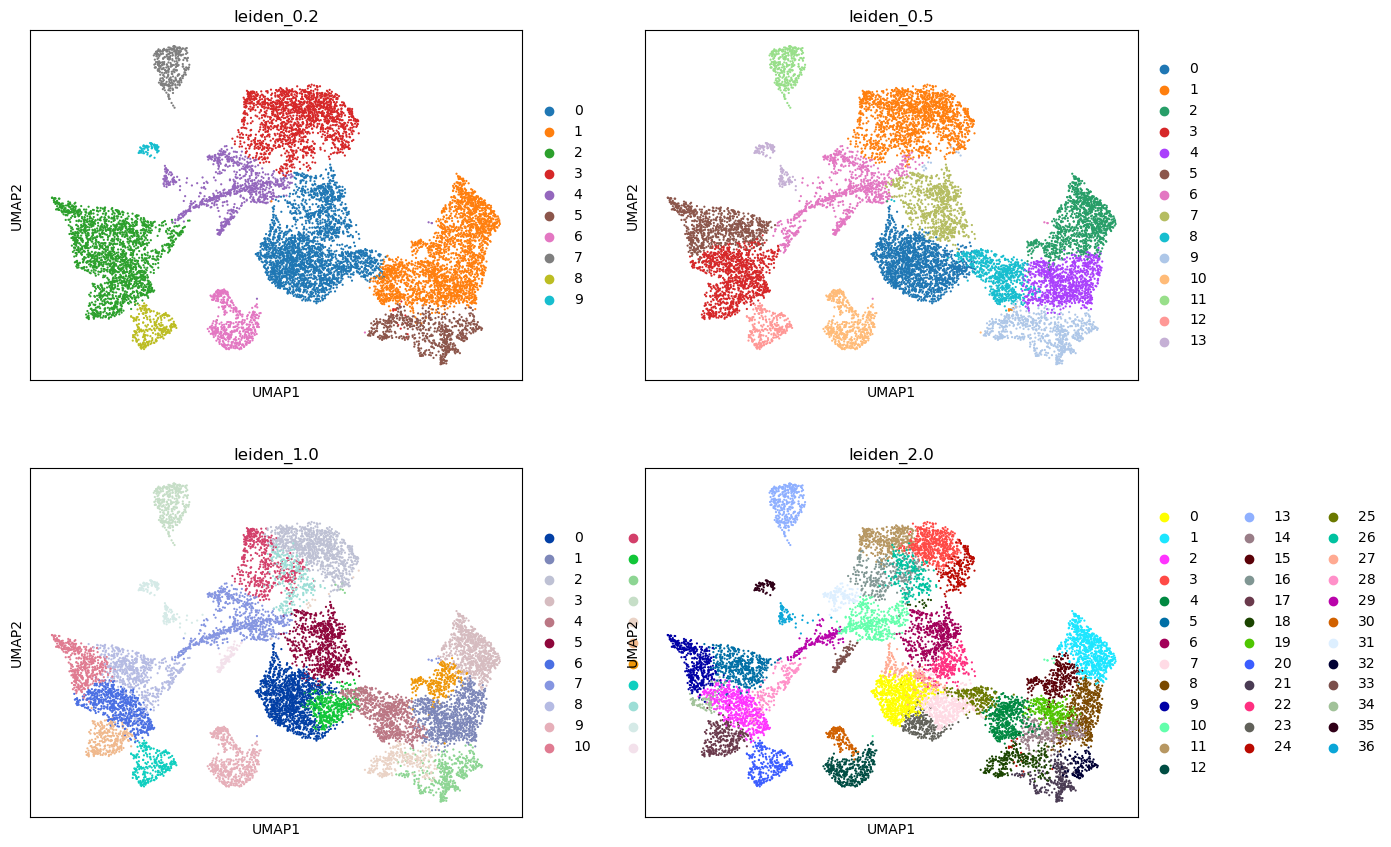

In [15]:
sc.pl.umap(adata, color=["leiden_0.2", "leiden_0.5", "leiden_1.0", "leiden_2.0"], ncols=2)



## Plotting the Clusters with examplary patches
We can use these cluster patches to filter out clusters that combine the background and save foreground images to a new adata object.

/tmp/ipykernel_82557/1864019945.py:37: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sample_id = sample_ids[i]  # Get Sample ID
/tmp/ipykernel_82557/1864019945.py:38: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  patch_id = patch_ids[i]  # Get Patch file name


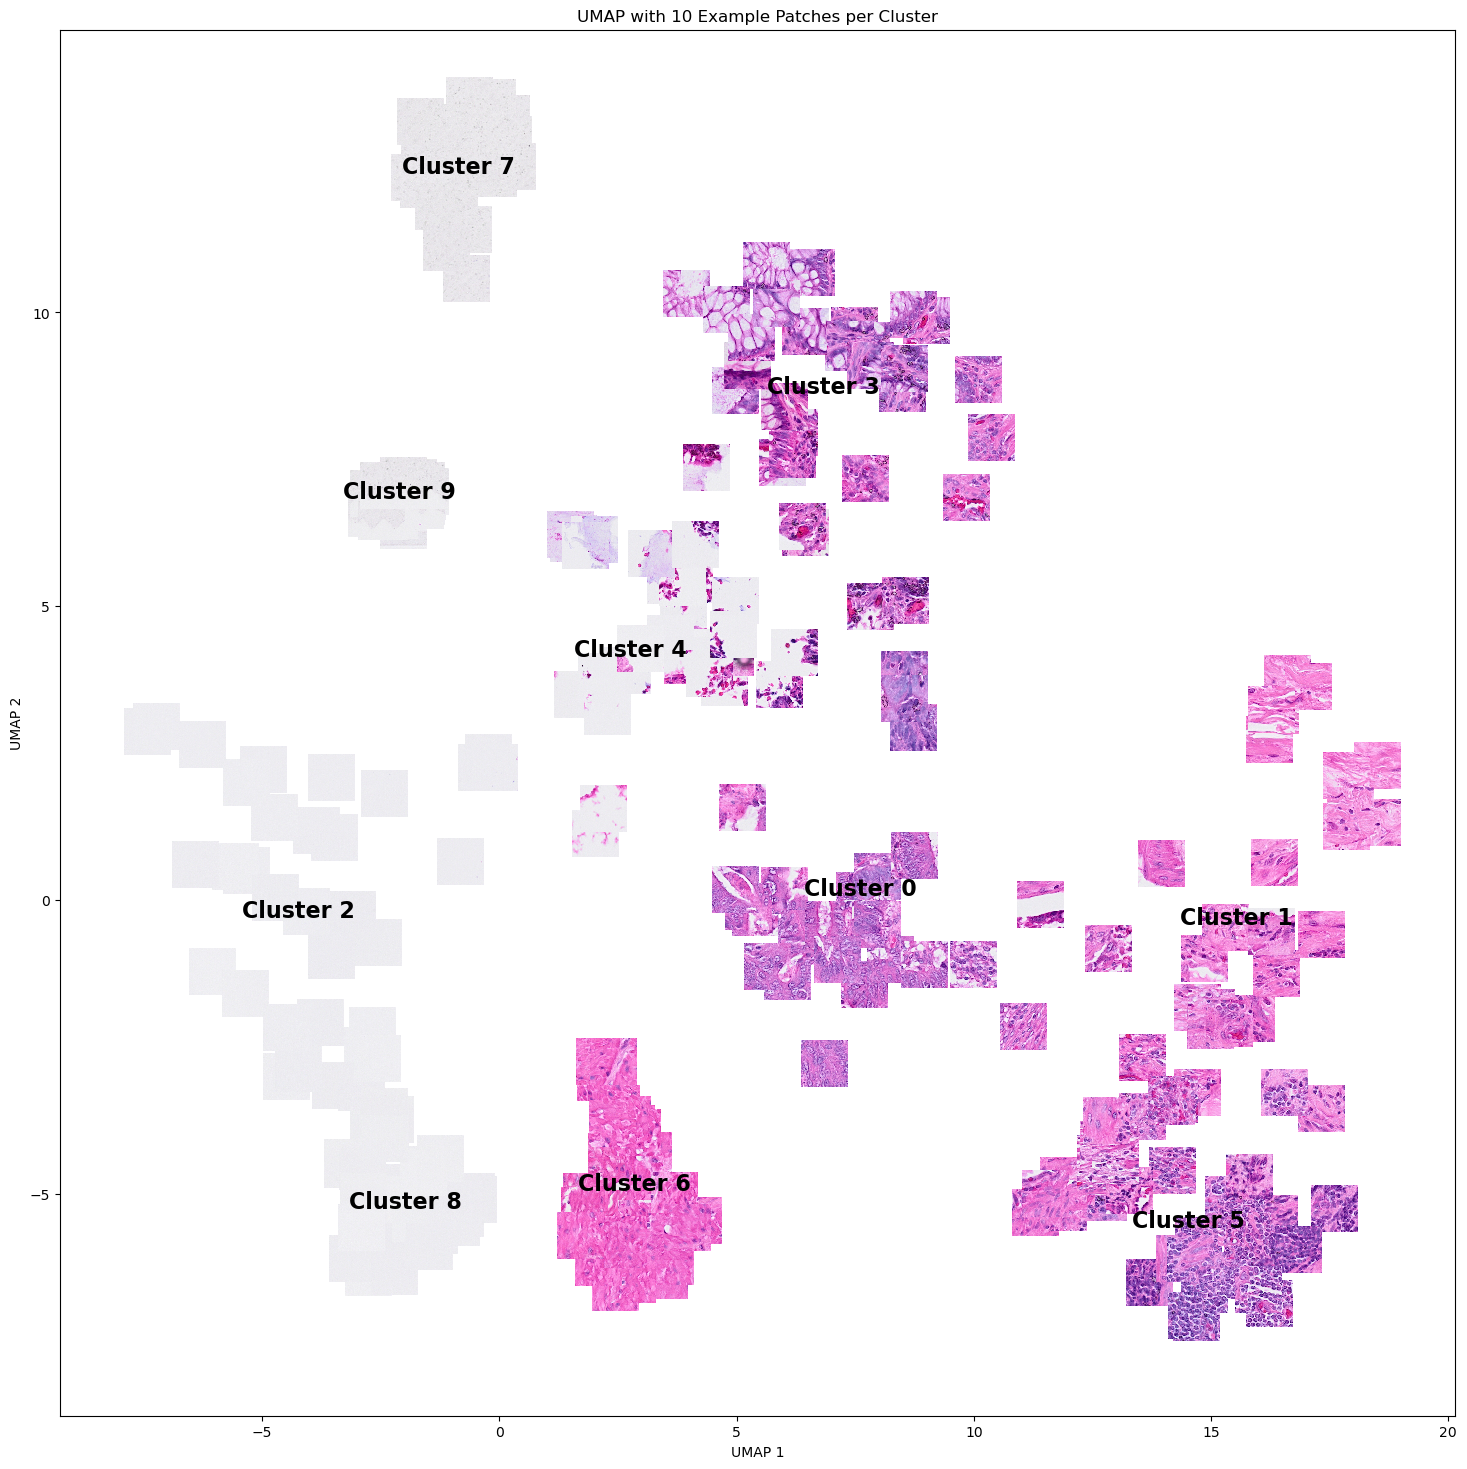

In [18]:
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import seaborn as sns
import random


umap_coords = adata.obsm["X_umap"]
clusters = adata.obs["leiden_0.2"].astype(str)  # Convert Leiden clusters to strings
sample_ids = adata.obs["Slide_ID"].astype(str)  # Get patient/sample IDs
patch_ids = adata.obs["Patch_ID"].astype(str)  # Get patch file names


patch_base_folder = "patches"


def getImage(path, zoom=0.15):  # Adjust zoom level for patch size
    return OffsetImage(plt.imread(path), zoom=zoom)


fig, ax = plt.subplots(figsize=(18, 18))
ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c="white", alpha=1, edgecolors="w", label="Cells")


for cluster in sorted(clusters.unique()):

    cluster_indices = np.where(clusters == cluster)[0]
    if len(cluster_indices) == 0:
        continue

    selected_indices = random.sample(list(cluster_indices), min(30, len(cluster_indices)))

 
    for i in selected_indices:
        x0, y0 = umap_coords[i]  # Get UMAP position
        sample_id = sample_ids[i]  # Get Sample ID
        patch_id = patch_ids[i]  # Get Patch file name

        patch_folder = os.path.join(patch_base_folder, sample_id)
        patch_path = os.path.join(patch_folder, patch_id)

        if not os.path.exists(patch_path):
            print(f"Warning: Missing patch {patch_path}")
            continue


        ab = AnnotationBbox(getImage(patch_path), (x0, y0), frameon=False, box_alignment=(0.5, 0.5), pad=0)
        ax.add_artist(ab)


    avg_x, avg_y = np.mean(umap_coords[cluster_indices], axis=0)
    ax.annotate(f"Cluster {cluster}", (avg_x, avg_y), fontsize=16, ha="center", color="black", weight="bold")


ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP with 10 Example Patches per Cluster")
fig.savefig('Umap_patches.pdf')

Use the following cell to filter out any cluster that only has background information. 

In [29]:
person = adata.obs["Slide_ID"].unique()[0]

patient_adata = adata
patient_adata.write(f"{patch_base_folder}/{person}/unfilteres_patch_embeddings.h5ad")
adata_filter=adata[~adata.obs["leiden_0.2"].isin(['2','7','8','9'])].copy()

In [20]:
adata_filter

AnnData object with n_obs × n_vars = 2805 × 1536
    obs: 'Slide_ID', 'Patch_ID', 'X', 'Y', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0'
    uns: 'pca', 'neighbors', 'umap', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0', 'leiden_0.2_colors', 'leiden_0.5_colors', 'leiden_1.0_colors', 'leiden_2.0_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

Now we only plot clusters with tissue in it. 

/tmp/ipykernel_82557/540592766.py:37: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sample_id = sample_ids[i]  # Get Sample ID
/tmp/ipykernel_82557/540592766.py:38: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  patch_id = patch_ids[i]  # Get Patch file name


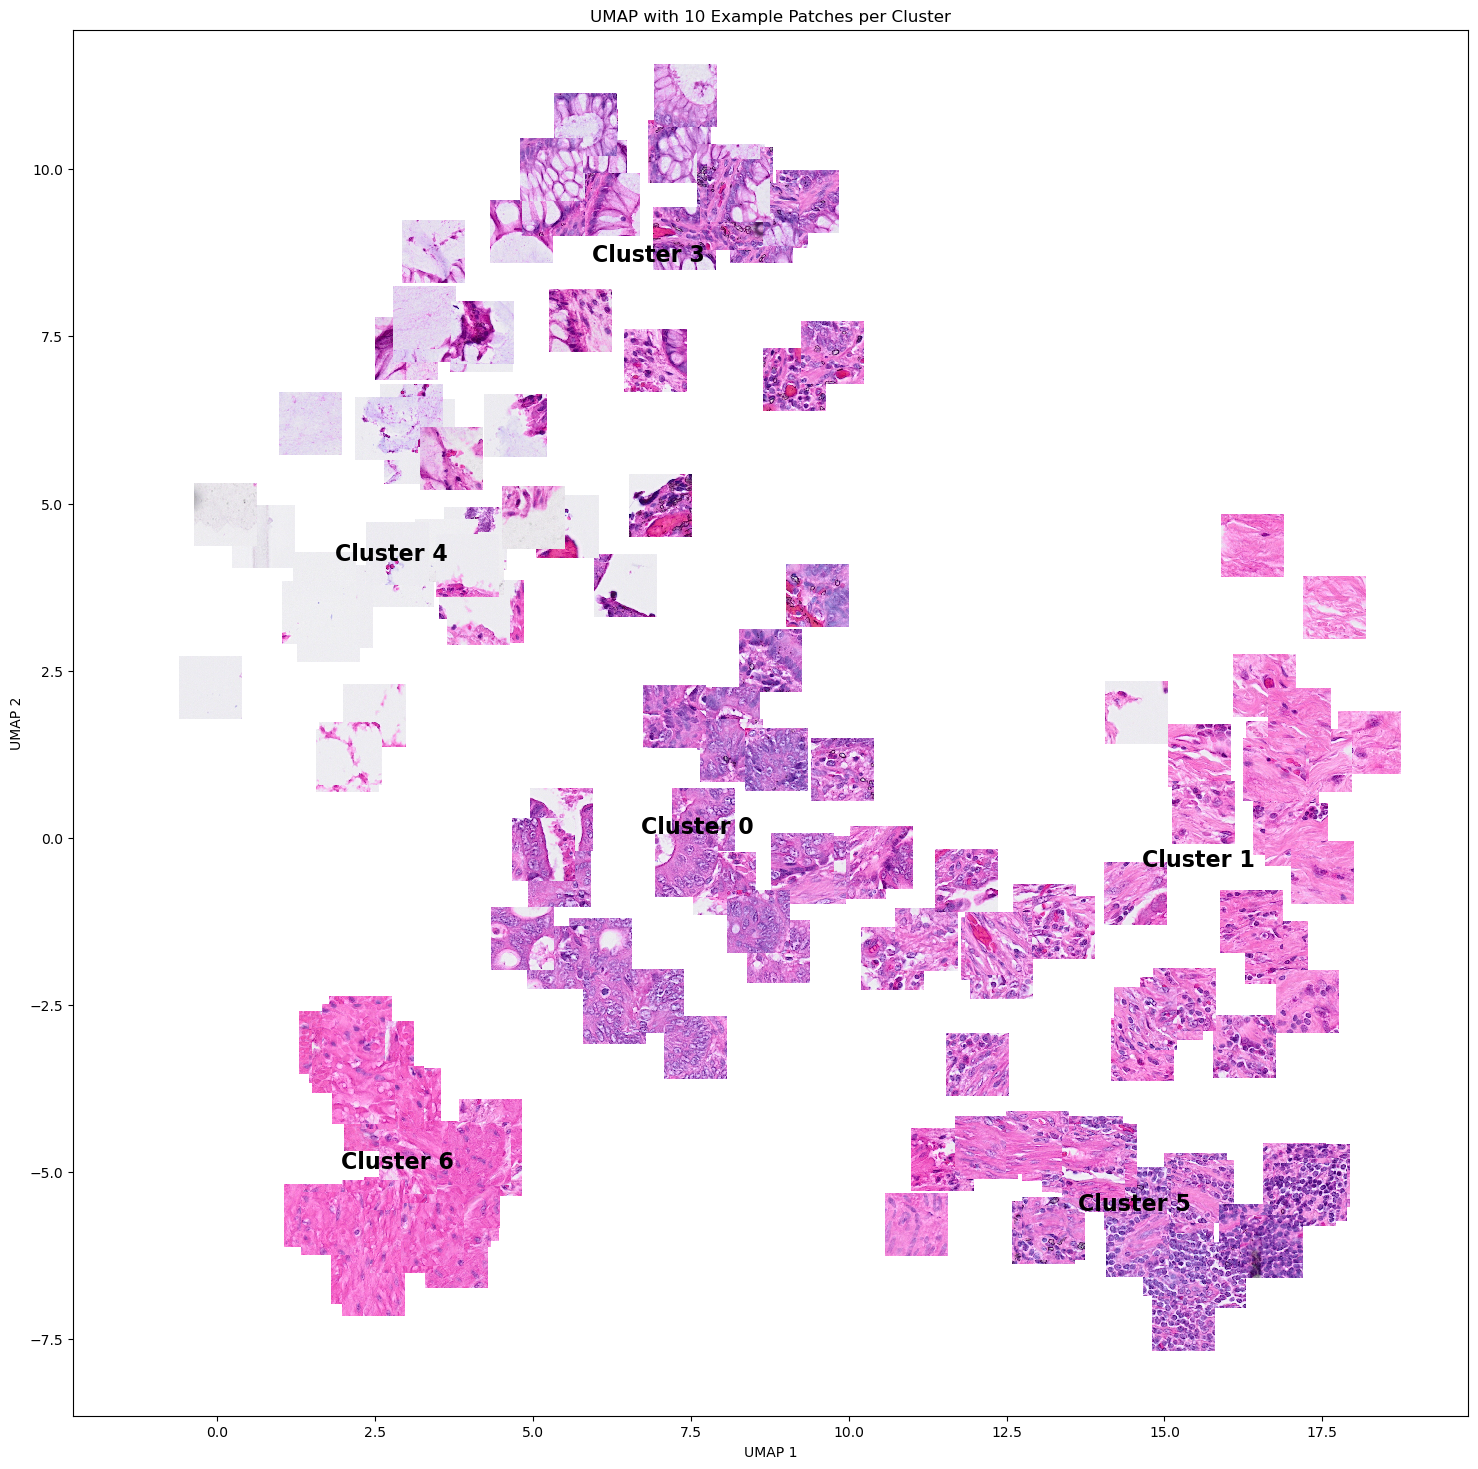

In [26]:
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import seaborn as sns
import random


umap_coords = adata_filter.obsm["X_umap"]
clusters = adata_filter.obs["leiden_0.2"].astype(str)  # Convert Leiden clusters to strings
sample_ids = adata_filter.obs["Slide_ID"].astype(str)  # Get patient/sample IDs
patch_ids = adata_filter.obs["Patch_ID"].astype(str)  # Get patch file names


patch_base_folder = "patches"


def getImage(path, zoom=0.2):  # Adjust zoom level for patch size
    return OffsetImage(plt.imread(path), zoom=zoom)


fig, ax = plt.subplots(figsize=(18, 18))
ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c="white", alpha=1, edgecolors="w", label="Cells")


for cluster in sorted(clusters.unique()):

    cluster_indices = np.where(clusters == cluster)[0]
    if len(cluster_indices) == 0:
        continue

    selected_indices = random.sample(list(cluster_indices), min(30, len(cluster_indices)))

 
    for i in selected_indices:
        x0, y0 = umap_coords[i]  # Get UMAP position
        sample_id = sample_ids[i]  # Get Sample ID
        patch_id = patch_ids[i]  # Get Patch file name

        patch_folder = os.path.join(patch_base_folder, sample_id)
        patch_path = os.path.join(patch_folder, patch_id)

        if not os.path.exists(patch_path):
            print(f"Warning: Missing patch {patch_path}")
            continue


        ab = AnnotationBbox(getImage(patch_path), (x0, y0), frameon=False, box_alignment=(0.5, 0.5), pad=0)
        ax.add_artist(ab)


    avg_x, avg_y = np.mean(umap_coords[cluster_indices], axis=0)
    ax.annotate(f"Cluster {cluster}", (avg_x, avg_y), fontsize=16, ha="center", color="black", weight="bold")


ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP with 10 Example Patches per Cluster")
fig.savefig('Umap_patches.pdf')

In [25]:
adata_filter

AnnData object with n_obs × n_vars = 9185 × 1536
    obs: 'Slide_ID', 'Patch_ID', 'X', 'Y', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0'
    uns: 'pca', 'neighbors', 'umap', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0', 'leiden_0.2_colors', 'leiden_0.5_colors', 'leiden_1.0_colors', 'leiden_2.0_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'